# HW1 — Introduction and Learnability: PAC vs Agnostic PAC

**M2 IMDS — Statistical and Machine Learning — Université de Haute-Alsace**

**Author:** Omar  Chellihi



In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED   = 42
rng    = np.random.default_rng(SEED)

THETA  = 0.3                    # target threshold
EPS    = 0.05                   # accuracy parameter
DELTA  = 0.1                    # confidence parameter
ETA    = 0.1                    # main label-noise rate (agnostic setting)
M_LIST = [5, 10, 20, 50, 100, 200]
M_EXT  = M_LIST + [500, 1000, 2000]
R      = 1000                   # repetitions per sample size
N_TEST = 200_000                # size of the independent test set

## 1. Data generation

`generate_data` draws $x_i\sim\mathcal U[0,1]$, labels them with $f_\theta$, and (if $\eta>0$) flips each label independently with probability $\eta$. Setting $\eta=0$ gives the realizable setting, so a single function covers both cases.

In [7]:
def target(x, theta=THETA):
    # f_theta(x) = 1 if x > theta else 0
    return (x > theta).astype(int)

def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    # Draw m i.i.d. examples: x ~ U[0,1], y = f_theta(x) with each label flipped w.p. eta.
    x = rng.uniform(0.0, 1.0, size=m)
    y = target(x, theta)
    if eta > 0:
        flip = rng.random(m) < eta
        y = np.where(flip, 1 - y, y)
    return x, y

# One realizable training set per required size
datasets = {m: generate_data(m) for m in M_LIST}
for m, (x, y) in datasets.items():
    print(f"m={m:>3}:  #label0={np.sum(y==0):>3}  #label1={np.sum(y==1):>3}  "
          f"(expected fraction of 1s = {1-THETA:.2f}, observed = {y.mean():.2f})")

m=  5:  #label0=  1  #label1=  4  (expected fraction of 1s = 0.70, observed = 0.80)
m= 10:  #label0=  1  #label1=  9  (expected fraction of 1s = 0.70, observed = 0.90)
m= 20:  #label0=  5  #label1= 15  (expected fraction of 1s = 0.70, observed = 0.75)
m= 50:  #label0= 17  #label1= 33  (expected fraction of 1s = 0.70, observed = 0.66)
m=100:  #label0= 29  #label1= 71  (expected fraction of 1s = 0.70, observed = 0.71)
m=200:  #label0= 64  #label1=136  (expected fraction of 1s = 0.70, observed = 0.68)


In [19]:
datasets.items()

dict_items([(5, (array([0.77395605, 0.43887844, 0.85859792, 0.69736803, 0.09417735]), array([1, 1, 1, 1, 0]))), (10, (array([0.97562235, 0.7611397 , 0.78606431, 0.12811363, 0.45038594,
       0.37079802, 0.92676499, 0.64386512, 0.82276161, 0.4434142 ]), array([1, 1, 1, 0, 1, 1, 1, 1, 1, 1]))), (20, (array([0.22723872, 0.55458479, 0.06381726, 0.82763117, 0.6316644 ,
       0.75808774, 0.35452597, 0.97069802, 0.89312112, 0.7783835 ,
       0.19463871, 0.466721  , 0.04380377, 0.15428949, 0.68304895,
       0.74476216, 0.96750973, 0.32582536, 0.37045971, 0.46955581]), array([0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1]))), (50, (array([0.18947136, 0.12992151, 0.47570493, 0.22690935, 0.66981399,
       0.43715192, 0.8326782 , 0.7002651 , 0.31236664, 0.8322598 ,
       0.80476436, 0.38747838, 0.2883281 , 0.6824955 , 0.13975248,
       0.1999082 , 0.00736227, 0.78692438, 0.66485086, 0.70516538,
       0.78072903, 0.45891578, 0.5687412 , 0.139797  , 0.11453007,
       0.66840296

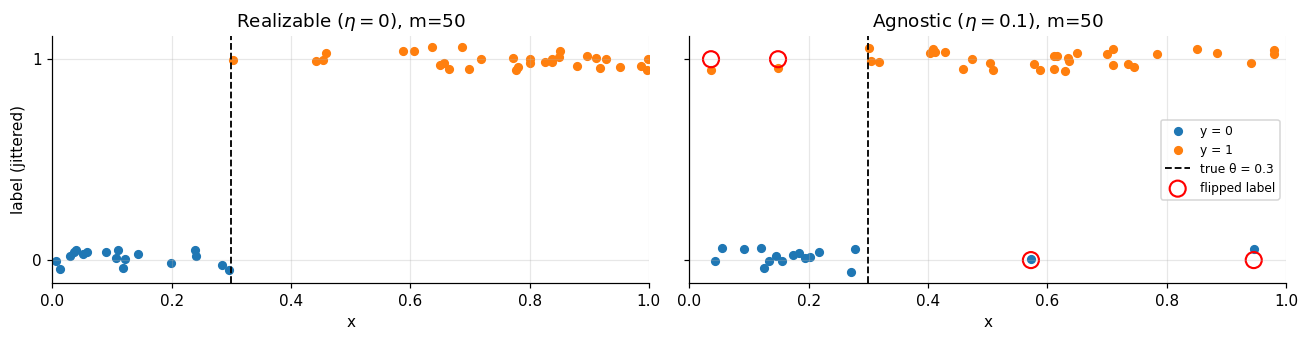

Agnostic sample: 4 of 50 labels flipped (expected ≈ 5).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
x_r, y_r = generate_data(50, eta=0.0)
x_n, y_n = generate_data(50, eta=ETA)
y_clean_n = target(x_n)

for ax, x, y, title in [(axes[0], x_r, y_r, "Realizable ($\\eta=0$), m=50"),
                        (axes[1], x_n, y_n, f"Agnostic ($\\eta={ETA}$), m=50")]:
    jitter = rng.uniform(-0.06, 0.06, size=len(x))
    ax.scatter(x[y == 0], y[y == 0] + jitter[y == 0], c="tab:blue", s=25, label="y = 0")
    ax.scatter(x[y == 1], y[y == 1] + jitter[y == 1], c="tab:orange", s=25, label="y = 1")
    ax.axvline(THETA, color="k", ls="--", lw=1.2, label=f"true θ = {THETA}")
    ax.set_title(title); ax.set_xlabel("x"); ax.set_yticks([0, 1]); ax.set_xlim(0, 1)

flipped = y_n != y_clean_n
axes[1].scatter(x_n[flipped], y_n[flipped], facecolors="none", edgecolors="red",
                s=110, lw=1.4, label="flipped label")
axes[0].set_ylabel("label (jittered)")
axes[1].legend(loc="center right", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Agnostic sample: {flipped.sum()} of 50 labels flipped (expected ≈ {ETA*50:.0f}).")

**Interpretation.** In the realizable sample, every point left of $\theta$ is labelled 0 and every point right of it is labelled 1: the data are perfectly separable by a threshold, and any threshold in the gap between the largest "0" and the smallest "1" is consistent. In the noisy sample, red-circled points carry the wrong label; they sit on the "wrong side" of $\theta$, so **no threshold can separate the sample perfectly**. This is the visual core of the difference between the two settings.

## 2. Implementation of ERM over thresholds

**Strategy.** Although $\mathcal H$ is infinite, the empirical error $L_S(h_t)$ only changes when $t$ crosses a training point. Hence it suffices to evaluate $m+1$ candidate thresholds: one in each interval between consecutive sorted points (plus the two ends).

After sorting $x_{(1)}\le\dots\le x_{(m)}$, placing the threshold just after the $k$-th point predicts 0 on the first $k$ points and 1 on the others, so the number of mistakes is

$$\text{err}(k)=\underbrace{\#\{i\le k: y_{(i)}=1\}}_{\text{1s predicted as 0}}+\underbrace{\#\{i>k: y_{(i)}=0\}}_{\text{0s predicted as 1}},\qquad k=0,\dots,m.$$

Both terms are obtained for **all $k$ at once with cumulative sums**, so ERM costs $O(m\log m)$ (sorting) instead of the naive $O(m^2)$.

**Choice of the returned threshold.** For the minimizing $k$ we return the **midpoint** $t=(x_{(k)}+x_{(k+1)})/2$ (with $x_{(0)}=0$, $x_{(m+1)}=1$). Every $t$ in that interval has the same empirical error; the midpoint is the natural "maximum-margin" choice. If several $k$ tie, we take the first one (any choice is a valid ERM).

A brute-force grid search is used below as a sanity check of the implementation.

In [9]:
def erm_threshold(x, y):
    # ERM over H = {x -> 1[x > t]}. Returns (t_hat, empirical_error).
    m = len(x)
    order = np.argsort(x)
    xs, ys = x[order], y[order]
    ones_left  = np.concatenate([[0], np.cumsum(ys)])                    # 1s among the first k points
    zeros_right = np.concatenate([[0], np.cumsum((1 - ys)[::-1])])[::-1]  # 0s among the last m-k points
    err = ones_left + zeros_right                                         # mistakes for k = 0..m
    k = int(np.argmin(err))
    padded = np.concatenate([[0.0], xs, [1.0]])
    t_hat = 0.5 * (padded[k] + padded[k + 1])
    return t_hat, err[k] / m

def empirical_error(t, x, y):
    return np.mean((x > t).astype(int) != y)

# --- sanity check against brute force on a fine grid ---
grid = np.linspace(0, 1, 20001)
for eta in [0.0, 0.2]:
    for m in [10, 50, 200]:
        x, y = generate_data(m, eta=eta)
        t_hat, e_hat = erm_threshold(x, y)
        brute = min(empirical_error(t, x, y) for t in grid)
        assert np.isclose(e_hat, brute) and np.isclose(e_hat, empirical_error(t_hat, x, y))
print("ERM matches brute-force grid search on all checks ✔")

ERM matches brute-force grid search on all checks ✔


## 3. Performance evaluation: empirical vs true error

For each training set we compute

* the **empirical error** $L_S(\hat h)$ on the training sample,
* the **true error** $L_\mathcal D(\hat h)$, estimated on an **independent test set** of $n_{test}=200\,000$ points drawn from the same distribution (noisy labels in the agnostic case),

and we check the test-set estimate against the closed form.

In [23]:

test_sets = {eta: generate_data(N_TEST, eta=eta) for eta in [0.0, ETA]}

def true_error_test(t, eta=0.0):
    xt, yt = test_sets[eta]
    return empirical_error(t, xt, yt)

print(f"{'m':>4} | {'t_hat':>7} | {'L_S':>6} | {'L_D (test)':>10} ")
print("-" * 50)
for m in M_LIST:
    x, y = datasets[m]
    t_hat, e_s = erm_threshold(x, y)
    print(f"{m:>4} | {t_hat:7.4f} | {e_s:6.3f} | {true_error_test(t_hat):10.4f} ")

   m |   t_hat |    L_S | L_D (test) 
--------------------------------------------------
   5 |  0.2665 |  0.000 |     0.0332 
  10 |  0.2495 |  0.000 |     0.0501 
  20 |  0.2765 |  0.000 |     0.0231 
  50 |  0.2988 |  0.000 |     0.0011 
 100 |  0.2962 |  0.000 |     0.0036 
 200 |  0.2989 |  0.000 |     0.0010 


**Interpretation.** In the realizable setting the empirical error of ERM is **always exactly 0** — a consistent threshold always exists — while the true error is positive and equals the probability mass between $\hat t$ and $\theta$. The true error shrinks quickly with $m$, because the gap between the largest "0" and the smallest "1" around $\theta$ narrows like $1/m$. The empirical error is therefore an *optimistic* estimate of performance: it says nothing about $L_\mathcal D$ on its own; the gap $L_\mathcal D-L_S$ is controlled only through sample size.

## 4. Experimental verification of PAC learning (realizable)

For every $m$ we repeat the experiment $R=1000$ times (fresh training sample each time) and estimate

$$\widehat{\Pr}\big(L_\mathcal D(\hat h)>\varepsilon\big)=\frac1R\sum_{r=1}^R\mathbb 1\big[L_\mathcal D(\hat h_r)>\varepsilon\big].$$

**Theoretical reference.** For thresholds, any consistent $\hat t$ lies between the largest point labelled 0 and the smallest labelled 1. Its error exceeds $\varepsilon$ only if no training point falls in $[\theta-\varepsilon,\theta]$ or none falls in $[\theta,\theta+\varepsilon]$, so

$$\Pr\big(L_\mathcal D(\hat h)>\varepsilon\big)\le 2(1-\varepsilon)^m\le 2e^{-\varepsilon m},\qquad\text{hence } m\ge\frac{\ln(2/\delta)}{\varepsilon}\;\Rightarrow\;\Pr(L_\mathcal D(\hat h)>\varepsilon)\le\delta .$$

The sample complexity scales as $1/\varepsilon$ — the fast "realizable" rate.

In [11]:
def run_experiment(m_list, eta=0.0, reps=R, use_test_set=True):
    # Returns dict m -> arrays (emp_err, true_err, t_hat) over `reps` repetitions.
    out = {}
    for m in m_list:
        emp, tru, ts = np.empty(reps), np.empty(reps), np.empty(reps)
        for r in range(reps):
            x, y = generate_data(m, eta=eta)
            t_hat, e = erm_threshold(x, y)
            emp[r], ts[r] = e, t_hat
            tru[r] = true_error_test(t_hat, eta) if use_test_set else true_error_analytic(t_hat, eta=eta)
        out[m] = dict(emp=emp, true=tru, t=ts)
    return out

res_real = run_experiment(M_LIST, eta=0.0)

m_star = np.ceil(np.log(2 / DELTA) / EPS)
print(f"Theoretical sample complexity for eps={EPS}, delta={DELTA}:  m >= {m_star:.0f}\n")
print(f"{'m':>4} | {'mean L_S':>8} | {'mean L_D':>8} | {'P(L_D>eps)':>10} | {'bound 2(1-eps)^m':>16}")
print("-" * 60)
for m in M_LIST:
    d = res_real[m]
    p = np.mean(d["true"] > EPS)
    print(f"{m:>4} | {d['emp'].mean():8.4f} | {d['true'].mean():8.4f} | {p:10.3f} | {min(1, 2*(1-EPS)**m):16.3f}")

Theoretical sample complexity for eps=0.05, delta=0.1:  m >= 60

   m | mean L_S | mean L_D | P(L_D>eps) | bound 2(1-eps)^m
------------------------------------------------------------
   5 |   0.0000 |   0.0702 |      0.559 |            1.000
  10 |   0.0000 |   0.0439 |      0.344 |            1.000
  20 |   0.0000 |   0.0239 |      0.114 |            0.717
  50 |   0.0000 |   0.0095 |      0.005 |            0.154
 100 |   0.0000 |   0.0051 |      0.000 |            0.012
 200 |   0.0000 |   0.0025 |      0.000 |            0.000


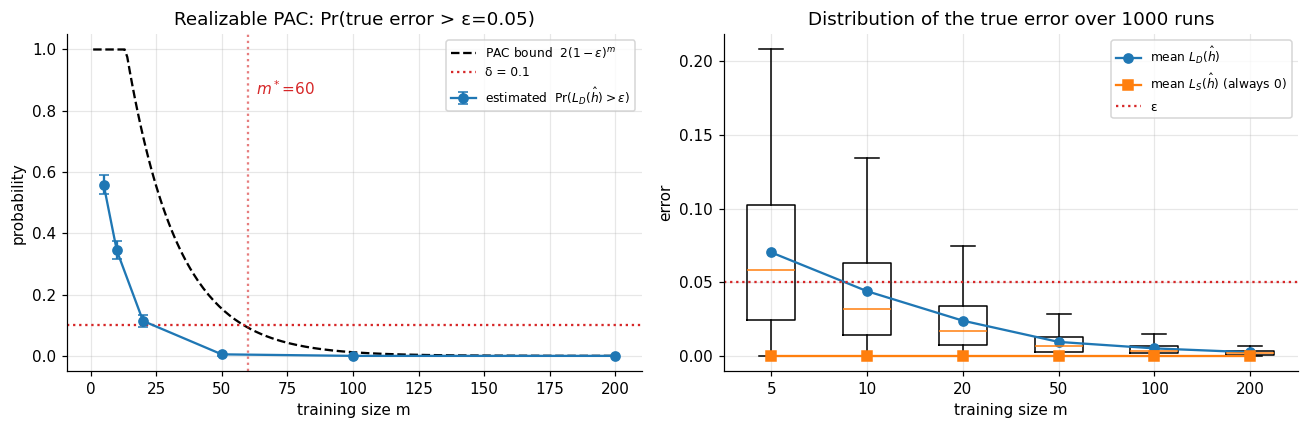

In [12]:
ms = np.array(M_LIST)
p_real = np.array([np.mean(res_real[m]["true"] > EPS) for m in M_LIST])
se = np.sqrt(p_real * (1 - p_real) / R)
m_fine = np.arange(1, 201)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.errorbar(ms, p_real, yerr=1.96 * se, fmt="o-", capsize=3, label="estimated  Pr($L_D(\\hat h) > \\varepsilon$)")
ax.plot(m_fine, np.minimum(1, 2 * (1 - EPS) ** m_fine), "k--", label="PAC bound  $2(1-\\varepsilon)^m$")
ax.axhline(DELTA, color="tab:red", ls=":", label=f"δ = {DELTA}")
ax.axvline(m_star, color="tab:red", ls=":", alpha=0.6)
ax.text(m_star + 3, 0.85, f"$m^*$={m_star:.0f}", color="tab:red")
ax.set_xlabel("training size m"); ax.set_ylabel("probability")
ax.set_title(f"Realizable PAC: Pr(true error > ε={EPS})"); ax.legend(fontsize=8)

ax = axes[1]
ax.boxplot([res_real[m]["true"] for m in M_LIST], positions=range(len(M_LIST)), widths=0.5, showfliers=False)
ax.plot(range(len(M_LIST)), [res_real[m]["true"].mean() for m in M_LIST], "o-", label="mean $L_D(\\hat h)$")
ax.plot(range(len(M_LIST)), [res_real[m]["emp"].mean() for m in M_LIST], "s-", label="mean $L_S(\\hat h)$ (always 0)")
ax.axhline(EPS, color="tab:red", ls=":", label="ε")
ax.set_xticks(range(len(M_LIST)), M_LIST); ax.set_xlabel("training size m"); ax.set_ylabel("error")
ax.set_title("Distribution of the true error over 1000 runs"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

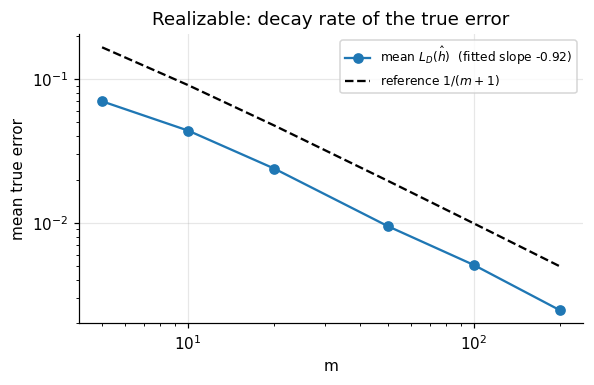

In [13]:
# Log-log view: how fast does the mean true error decay?
mean_true = np.array([res_real[m]["true"].mean() for m in M_LIST])
slope = np.polyfit(np.log(ms), np.log(mean_true), 1)[0]
plt.figure(figsize=(5.5, 3.6))
plt.loglog(ms, mean_true, "o-", label=f"mean $L_D(\\hat h)$  (fitted slope {slope:.2f})")
plt.loglog(ms, 1 / (ms + 1), "k--", label="reference $1/(m+1)$")
plt.xlabel("m"); plt.ylabel("mean true error"); plt.title("Realizable: decay rate of the true error")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation.**

* $\Pr(L_\mathcal D(\hat h)>\varepsilon)$ is close to 1 for very small samples and **drops to essentially 0** as $m$ grows. It goes below $\delta=0.1$ before the theoretical $m^\star$, as expected since $2(1-\varepsilon)^m$ is an upper bound (union bound over the two sides of $\theta$, and a worst case over consistent hypotheses, whereas our midpoint rule is better than the worst consistent hypothesis).
* The empirical curve always lies **below** the bound, confirming the PAC guarantee empirically: $\mathcal H$ is PAC-learnable and ERM is a successful PAC learner.
* The mean true error decays with a log-log slope close to $-1$, i.e. **$L_\mathcal D(\hat h)=O(1/m)$**. This is the fast realizable rate, equivalent to a sample complexity $m=O\!\left(\frac{1}{\varepsilon}\log\frac1\delta\right)$.

## 5. From PAC to Agnostic PAC (label noise)

We now flip each label with probability $\eta$. Two consequences change *what* must be measured:

1. Every hypothesis has true error $\ge\eta$ (the noise is irreducible). With $\eta=0.1>\varepsilon=0.05$, we get $\Pr(L_\mathcal D(\hat h)>\varepsilon)=1$ **for every $m$** — the PAC criterion simply cannot be met.
2. The Agnostic PAC criterion compares with the best hypothesis in the class:
$$\Pr\Big(L_\mathcal D(\hat h)>\min_{h\in\mathcal H}L_\mathcal D(h)+\varepsilon\Big)\le\delta,\qquad\min_{h\in\mathcal H}L_\mathcal D(h)=\eta .$$
So we track the **excess risk** $L_\mathcal D(\hat h)-\eta$.

**Theoretical reference.** Agnostic learnability comes from **uniform convergence**: if $\sup_{h}|L_S(h)-L_\mathcal D(h)|\le\varepsilon/2$ then ERM is $\varepsilon$-optimal. With VC-dimension 1 the sample complexity scales as $m=O\!\left(\frac{1}{\varepsilon^2}\log\frac1\delta\right)$, i.e. the excess risk decays like $O(1/\sqrt m)$ in the worst case — **slower than in the realizable case**. The specific noise model here (Massart noise with margin $1-2\eta$) is benign and can do better, so we measure the actual rate rather than assume it.

In [14]:
res_agn = run_experiment(M_EXT, eta=ETA)

print(f"Agnostic setting, eta = {ETA}  (best achievable risk L* = {ETA})\n")
print(f"{'m':>5} | {'mean L_S':>8} | {'mean L_D':>8} | {'P(L_S=0)':>8} | {'P(L_D>eps)':>10} | {'P(L_D-L*>eps)':>13}")
print("-" * 70)
for m in M_EXT:
    d = res_agn[m]
    print(f"{m:>5} | {d['emp'].mean():8.4f} | {d['true'].mean():8.4f} | {np.mean(d['emp']==0):8.3f} | "
          f"{np.mean(d['true']>EPS):10.3f} | {np.mean(d['true']-ETA>EPS):13.3f}")

Agnostic setting, eta = 0.1  (best achievable risk L* = 0.1)

    m | mean L_S | mean L_D | P(L_S=0) | P(L_D>eps) | P(L_D-L*>eps)
----------------------------------------------------------------------
    5 |   0.0598 |   0.1908 |    0.723 |      1.000 |         0.626
   10 |   0.0780 |   0.1598 |    0.448 |      1.000 |         0.422
   20 |   0.0868 |   0.1393 |    0.140 |      1.000 |         0.257
   50 |   0.0956 |   0.1154 |    0.003 |      1.000 |         0.059
  100 |   0.0968 |   0.1081 |    0.000 |      1.000 |         0.010
  200 |   0.0988 |   0.1045 |    0.000 |      1.000 |         0.002
  500 |   0.0991 |   0.1021 |    0.000 |      1.000 |         0.000
 1000 |   0.0997 |   0.1012 |    0.000 |      1.000 |         0.000
 2000 |   0.0999 |   0.1008 |    0.000 |      1.000 |         0.000


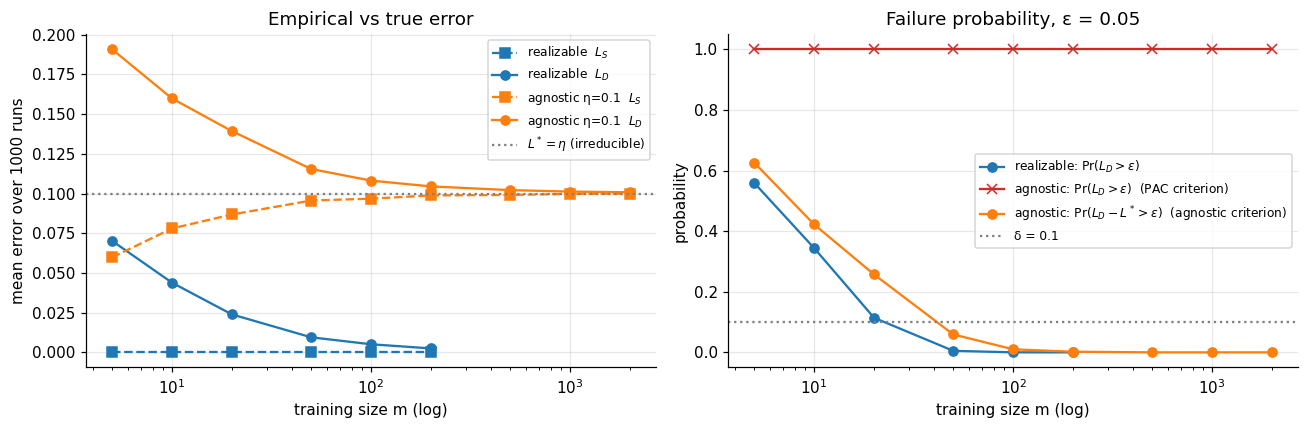

In [15]:
ms_ext = np.array(M_EXT)
emp_real  = [res_real[m]["emp"].mean() for m in M_LIST]
true_real = [res_real[m]["true"].mean() for m in M_LIST]
emp_agn   = [res_agn[m]["emp"].mean() for m in M_EXT]
true_agn  = [res_agn[m]["true"].mean() for m in M_EXT]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(M_LIST, emp_real, "s--", c="tab:blue", label="realizable  $L_S$")
ax.plot(M_LIST, true_real, "o-", c="tab:blue", label="realizable  $L_D$")
ax.plot(M_EXT, emp_agn, "s--", c="tab:orange", label=f"agnostic η={ETA}  $L_S$")
ax.plot(M_EXT, true_agn, "o-", c="tab:orange", label=f"agnostic η={ETA}  $L_D$")
ax.axhline(ETA, color="gray", ls=":", label="$L^*=\\eta$ (irreducible)")
ax.set_xscale("log"); ax.set_xlabel("training size m (log)"); ax.set_ylabel("mean error over 1000 runs")
ax.set_title("Empirical vs true error"); ax.legend(fontsize=8)

ax = axes[1]
p_pac  = [np.mean(res_agn[m]["true"] > EPS) for m in M_EXT]
p_apac = [np.mean(res_agn[m]["true"] - ETA > EPS) for m in M_EXT]
ax.plot(M_LIST, p_real, "o-", c="tab:blue", label="realizable: Pr($L_D>\\varepsilon$)")
ax.plot(M_EXT, p_pac, "x-", c="tab:red", label="agnostic: Pr($L_D>\\varepsilon$)  (PAC criterion)")
ax.plot(M_EXT, p_apac, "o-", c="tab:orange", label="agnostic: Pr($L_D-L^*>\\varepsilon$)  (agnostic criterion)")
ax.axhline(DELTA, color="gray", ls=":", label=f"δ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("training size m (log)"); ax.set_ylabel("probability")
ax.set_title(f"Failure probability, ε = {EPS}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**

* **Left.** With noise, the empirical error no longer sits at 0: it fluctuates around $\eta$ and is *below* the true error (ERM chooses the threshold that best fits the particular noise realisation — mild overfitting). The true error decreases towards $\eta$, never below it. The gap $L_\mathcal D-L_S$ shrinks with $m$: this is uniform convergence at work.
* **Right.** The PAC criterion (red) stays at probability 1 for all $m$: no amount of data makes $L_\mathcal D(\hat h)\le\varepsilon$ when $\varepsilon<\eta$. The agnostic criterion (orange) does go to 0, but **more slowly** than the realizable curve (blue) — more samples are required for the same $(\varepsilon,\delta)$.

### 5.1 Can the empirical error still reach zero?

$L_S(\hat h)=0$ requires that, by chance, no flipped label lands on the "wrong side" of the sample. Below we plot its frequency and the full distribution of $L_S(\hat h)$.

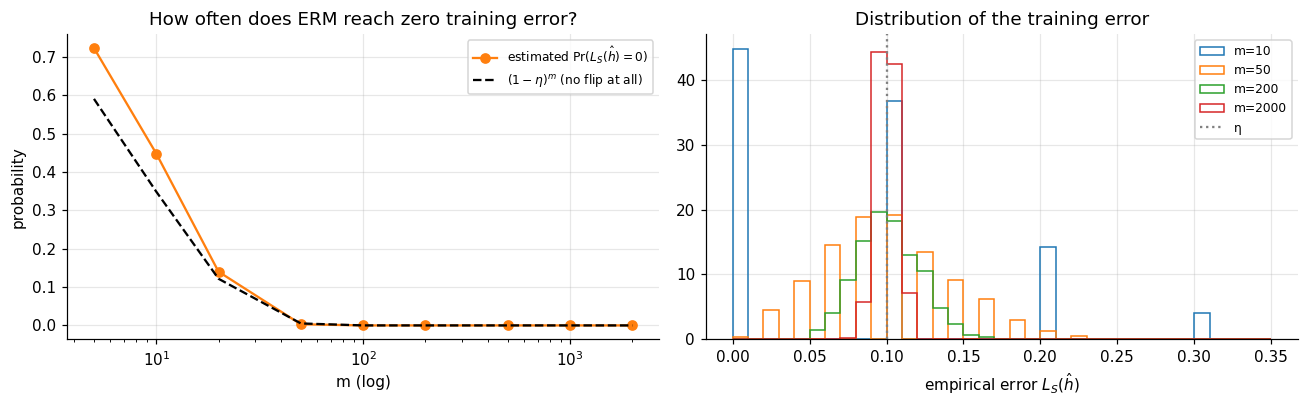

In [16]:
p_zero = [np.mean(res_agn[m]["emp"] == 0) for m in M_EXT]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(M_EXT, p_zero, "o-", c="tab:orange", label="estimated Pr($L_S(\\hat h)=0$)")
axes[0].plot(ms_ext, (1 - ETA) ** ms_ext, "k--", label="$(1-\\eta)^m$ (no flip at all)")
axes[0].set_xscale("log"); axes[0].set_xlabel("m (log)"); axes[0].set_ylabel("probability")
axes[0].set_title("How often does ERM reach zero training error?"); axes[0].legend(fontsize=8)

for m in [10, 50, 200, 2000]:
    axes[1].hist(res_agn[m]["emp"], bins=np.linspace(0, 0.35, 36), histtype="step", lw=1.6, density=True, label=f"m={m}")
axes[1].axvline(ETA, color="gray", ls=":", label="η")
axes[1].set_xlabel("empirical error $L_S(\\hat h)$"); axes[1].set_title("Distribution of the training error")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Answer.** Only by luck, and only for tiny samples. For $m=5$ or $10$ a sizeable fraction of runs still have $L_S=0$ (either no label is flipped, or the flips happen to remain consistent with *some* threshold — which is why the estimate is above $(1-\eta)^m$). The probability decays exponentially and is essentially 0 from $m\approx 50$ on. The training error concentrates around $\eta$ (slightly below it, due to ERM's optimistic bias), with a spread that shrinks like $1/\sqrt m$. A zero training error is now a *sign of overfitting the noise*, not of perfect learning.

### 5.2 Does more data still improve generalization? Effect of the noise level

We repeat the experiment for several noise rates $\eta\in\{0,0.05,0.1,0.2,0.3\}$ and track the **excess risk** $L_\mathcal D(\hat h)-\eta$. To keep the computation fast we use the exact formula for $L_\mathcal D$ here (validated in Section 3).

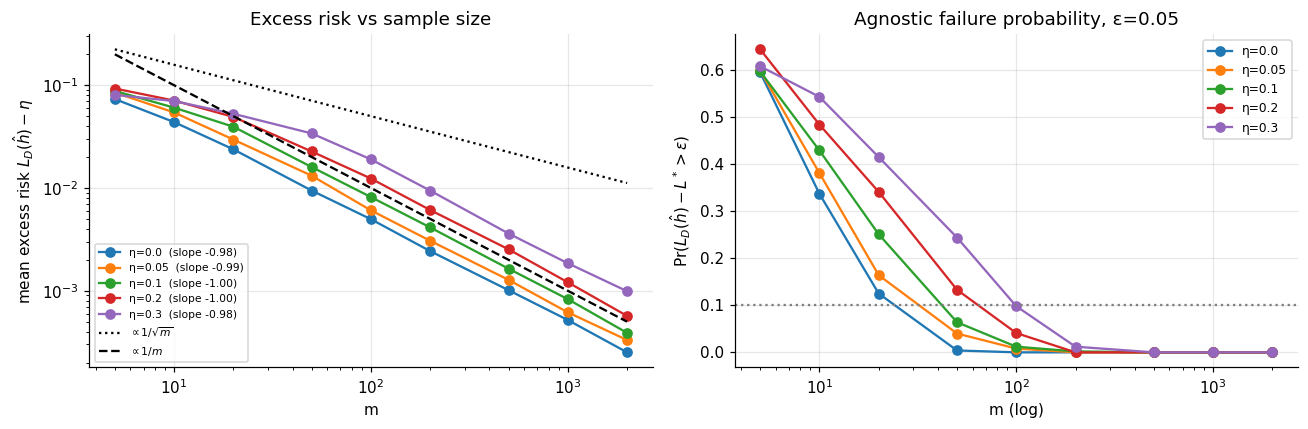

Smallest m in the grid with Pr(excess > eps) <= delta:
  eta=0.0 : m = 50
  eta=0.05: m = 50
  eta=0.1 : m = 50
  eta=0.2 : m = 100
  eta=0.3 : m = 100


In [17]:
ETAS = [0.0, 0.05, 0.1, 0.2, 0.3]
res_eta = {eta: run_experiment(M_EXT, eta=eta, use_test_set=False) for eta in ETAS}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for eta in ETAS:
    exc = np.array([np.mean(res_eta[eta][m]["true"] - eta) for m in M_EXT])
    p   = np.array([np.mean(res_eta[eta][m]["true"] - eta > EPS) for m in M_EXT])
    slope = np.polyfit(np.log(ms_ext[3:]), np.log(exc[3:]), 1)[0]
    axes[0].loglog(ms_ext, exc, "o-", label=f"η={eta}  (slope {slope:.2f})")
    axes[1].semilogx(ms_ext, p, "o-", label=f"η={eta}")
axes[0].loglog(ms_ext, 0.5 / np.sqrt(ms_ext), "k:", label="$\\propto 1/\\sqrt{m}$")
axes[0].loglog(ms_ext, 1 / ms_ext, "k--", label="$\\propto 1/m$")
axes[0].set_xlabel("m"); axes[0].set_ylabel("mean excess risk $L_D(\\hat h)-\\eta$")
axes[0].set_title("Excess risk vs sample size"); axes[0].legend(fontsize=7)
axes[1].axhline(DELTA, color="gray", ls=":")
axes[1].set_xlabel("m (log)"); axes[1].set_ylabel("Pr($L_D(\\hat h)-L^*>\\varepsilon$)")
axes[1].set_title(f"Agnostic failure probability, ε={EPS}"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Smallest m in the grid with Pr(excess > eps) <= delta:")
for eta in ETAS:
    ok = [m for m in M_EXT if np.mean(res_eta[eta][m]["true"] - eta > EPS) <= DELTA]
    print(f"  eta={eta:<4}: m = {ok[0] if ok else '> 2000'}")

**Answer.** **Yes** — increasing $m$ still improves generalization in the agnostic sense: the excess risk $L_\mathcal D(\hat h)-L^\star$ goes to 0 and the agnostic failure probability goes to 0 for every $\eta<1/2$. But:

* the true error converges to $\eta$, **not to 0**: beyond some point extra data only brings $\hat h$ closer to the best threshold, it cannot remove label noise;
* **the more noise, the more data are needed** to reach the same $(\varepsilon,\delta)$; the curves shift to the right as $\eta$ grows, because labels near $\theta$ carry less information (the effective margin $1-2\eta$ shrinks), and the variance of the empirical error is larger.

Note on the observed rate: in this particular noise model the noise is *independent of $x$* and $<1/2$ (Massart noise), so the excess risk of ERM still decays almost like $1/m$, with a constant that grows with $\eta$. The $1/\sqrt m$ rate of the agnostic theory is a **worst-case guarantee over all distributions** — it is what one gets for adversarial noise concentrated near the boundary, and it is the rate followed by the deviation $|L_S-L_\mathcal D|$ (next cell).

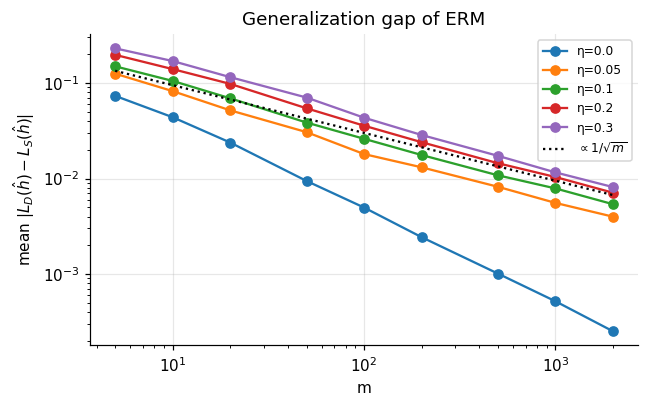

In [18]:
# Generalization gap |L_D - L_S| of the ERM hypothesis: the quantity uniform convergence controls.
plt.figure(figsize=(6, 3.8))
for eta in ETAS:
    gap = np.array([np.mean(np.abs(res_eta[eta][m]["true"] - res_eta[eta][m]["emp"])) for m in M_EXT])
    plt.loglog(ms_ext, np.maximum(gap, 1e-5), "o-", label=f"η={eta}")
plt.loglog(ms_ext, 0.3 / np.sqrt(ms_ext), "k:", label="$\\propto 1/\\sqrt{m}$")
plt.xlabel("m"); plt.ylabel("mean $|L_D(\\hat h) - L_S(\\hat h)|$")
plt.title("Generalization gap of ERM"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation.** In the realizable case the gap equals $L_\mathcal D(\hat h)$ itself ($L_S=0$) and decays like $1/m$. As soon as $\eta>0$, the empirical error is a sum of Bernoulli($\approx\eta$) variables whose fluctuations are of order $\sqrt{\eta(1-\eta)/m}$, so the gap between training and true error decays at the **$1/\sqrt m$ rate** predicted by Hoeffding's inequality / uniform convergence. This is the mechanism behind the $1/\varepsilon^2$ sample complexity of Agnostic PAC: one needs $m\sim 1/\varepsilon^2$ samples just for $L_S$ to be an $\varepsilon$-accurate estimate of $L_\mathcal D$.

### 5.3 Relation to the PAC and Agnostic PAC frameworks

| | **PAC (realizable)** | **Agnostic PAC** |
|---|---|---|
| Assumption | $\exists h^\star\in\mathcal H$ with $L_\mathcal D(h^\star)=0$ | none on the labels |
| Guarantee | $\Pr(L_\mathcal D(\hat h)>\varepsilon)\le\delta$ | $\Pr(L_\mathcal D(\hat h)>\min_{\mathcal H}L_\mathcal D+\varepsilon)\le\delta$ |
| ERM training error | always $0$ | $\approx\eta>0$; zero only by chance for tiny $m$ |
| Limit of $L_\mathcal D(\hat h)$ | $0$ | $L^\star=\eta$ |
| Sample complexity | $O\!\left(\frac{1}{\varepsilon}\log\frac1\delta\right)$ | $O\!\left(\frac{1}{\varepsilon^2}\log\frac1\delta\right)$ (worst case) |
| Key tool | probability that no point falls in a bad region | uniform convergence (Hoeffding + VC dim = 1) |

Our experiments match these statements: in the realizable case the failure probability falls below the bound $2(1-\varepsilon)^m$ and the true error decays like $1/m$; with noise the PAC criterion fails for every $m$ (because $\varepsilon<\eta$), whereas the agnostic criterion holds for large enough $m$, with larger samples required as $\eta$ grows. The fact that the same algorithm (ERM) succeeds in both settings illustrates the fundamental theorem: since $\mathrm{VCdim}(\mathcal H)=1<\infty$, the class has the uniform convergence property, so it is agnostic PAC learnable by ERM — and in particular PAC learnable.

## Conclusion

* **Realizable (PAC).** ERM always attains zero training error, and its true error drops quickly (≈ $1/m$). With $\varepsilon=0.05$, $\delta=0.1$, the probability of a bad hypothesis falls below $\delta$ within the tested range ($m\le 200$), comfortably under the theoretical bound $2(1-\varepsilon)^m$ and before the predicted $m^\star=60$.
* **Agnostic.** With label noise $\eta$, the training error no longer reaches zero (except by chance on tiny samples) and the true error is bounded below by $\eta$. Asking for $L_\mathcal D(\hat h)\le\varepsilon$ is hopeless when $\varepsilon<\eta$: the PAC failure probability stays at 1 whatever the sample size. The meaningful goal becomes **competing with the best hypothesis in the class**, $L_\mathcal D(\hat h)\le\eta+\varepsilon$.
* **More data still helps, but less.** The excess risk and the agnostic failure probability go to 0, but more samples are needed than in the realizable case, and increasingly so as $\eta$ grows. The gap between training and test error shrinks only at the $1/\sqrt m$ rate of uniform convergence, which explains the $1/\varepsilon^2$ (vs $1/\varepsilon$) sample complexity of Agnostic PAC.
* **Take-away.** PAC learning answers "can we reach (almost) zero error?" and relies on realizability; Agnostic PAC answers "can we get (almost) as good as the best model in our class?" and holds without any assumption on the labels, at the price of slower learning and a non-zero error floor.